<font size=7 color="#5499C7" >Assignment 1: Image Processing Fundamentals</font>
- <font size=5>__Group Members__ : Kourosh Sajjadi - Kasra Noorbakhsh</font>
- <font size=5>__Student IDs__  : 810100587 - 810100230</font> 
- <font size=5>__Course__ : Computer Vision</font> 

In [1]:
import cv2
import numpy as np

from plotting import *
from filters import apply_filter

In [2]:
%matplotlib inline

In [3]:
IMAGE_PATH = "Data/Pic.jpg"
VIDEO_PATH = "Data/Original_Vid.mp4"

Original Image Details:
Image Format:  <class 'numpy.ndarray'>
Data Type:  uint8
Shape (Height, Width, Channels):  (600, 800, 3)
Otsu's Optimal Threshold Value: 106.0


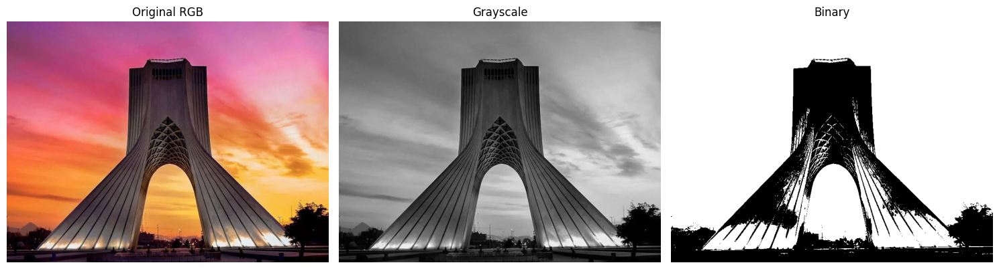

In [4]:
image = cv2.imread(IMAGE_PATH)

if image is not None:
    print("Original Image Details:")

    print("Image Format: ", type(image))
    print("Data Type: ", image.dtype)
    print("Shape (Height, Width, Channels): ", image.shape)

    imageRGB = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    grayImage = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    _, binaryOtsu = cv2.threshold(grayImage, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    print("Otsu's Optimal Threshold Value:", _)
    _, binaryImage = cv2.threshold(grayImage, 82, 255, cv2.THRESH_BINARY)

    plotImageComparisons(
        images=[imageRGB, grayImage, binaryImage],
        titles=["Original RGB", "Grayscale", "Binary"],
        cols=3,
        figsize=(15, 5)
    )

else:
    print(f"Error: Could not load image from {IMAGE_PATH}")

<p align="justify"><font size="6" color="#A9CCE3"><b>Image Thresholding Analysis</b></font><br></p>

<p align="justify">
We experimented with multiple thresholding approaches to convert the grayscale image to binary format.
Initially, we tried Otsu's method which automatically determines the optimal threshold value by
minimizing intra-class variance and maximizing inter-class variance between the foreground and background.
However, after careful analysis of the results, we found that a fixed threshold value of 82
provided superior performance for our specific image, yielding better contrast and preserving
important image details compared to Otsu's method.

The threshold value of 82 was determined through empirical testing and visual inspection of the results,
ensuring that the binary image maintains good separation between foreground and background while
retaining important structural features of the original image.
</p>

<p align="justify"><font size="6" color="#A9CCE3"><b>RGB, Grayscale, and Binary Image Processing Explained</b></font><br></p>

<p align="justify">
<font size="4" color="#5DADE2"><b>🌈 RGB (Red, Green, Blue) Images:</b></font><br>
RGB images are color images that store color information using three color channels — Red, Green, and Blue.
Each pixel in an RGB image contains three values (typically ranging from 0–255) that represent the intensity
of each color component. By combining these three values, the image can represent millions of different colors.
This color model is based on the way human eyes perceive color and is widely used in digital imaging and display systems.
</p>

<p align="justify">
<font size="4" color="#5DADE2"><b>⚪ Grayscale Images:</b></font><br>
Grayscale images, also known as monochromatic images, contain only intensity information without color.
Each pixel in a grayscale image is represented by a single value indicating brightness level,
typically ranging from 0 (black) to 255 (white). Grayscale images are often used in image processing tasks
because they reduce computational complexity while preserving essential structural information.
Conversion from RGB to grayscale typically uses a weighted average of the three color channels to account
for human perception sensitivity, often using the formula: 0.299R + 0.587G + 0.114B.
</p>

<p align="justify">
<font size="4" color="#5DADE2"><b>⬛ Binary Images:</b></font><br>
Binary images are the simplest form of digital images where each pixel can have only one of two possible values —
typically 0 (black) or 1/255 (white). Binary images are created by applying a threshold value to grayscale
images: pixels with intensity values above the threshold become white, while those below become black.
This extreme simplification removes all gradations of gray and is particularly useful for image segmentation,
object detection, character recognition, and morphological operations. Binary images require minimal storage
space and allow for fast processing, though they lose significant detail compared to grayscale or RGB images.
</p>

<p align="justify">
The transformation from RGB to Grayscale to Binary represents a progressive reduction in information complexity,
each stage serving distinct purposes in computer vision and image analysis applications.
</p>


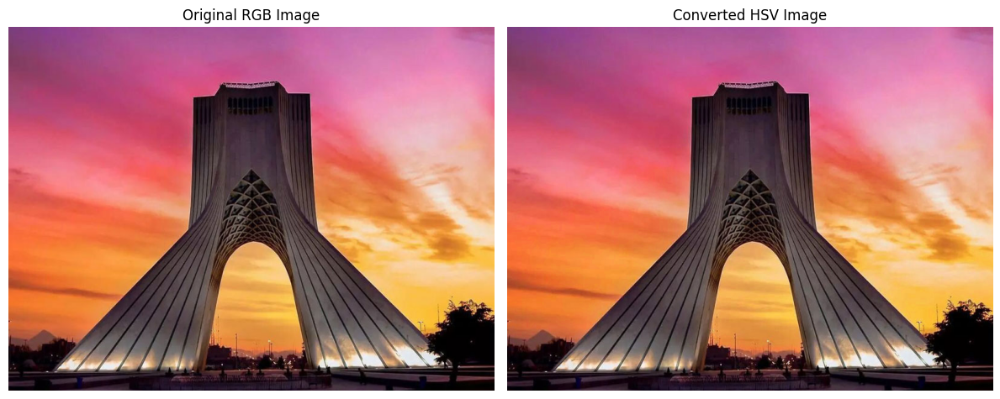

In [5]:
imageHSV = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
hsvAsRgb = cv2.cvtColor(imageHSV, cv2.COLOR_HSV2RGB)

plotImageComparisons(
    images=[imageRGB, hsvAsRgb],
    titles=["Original RGB Image", "Converted HSV Image"],
    cols=2,
    figsize=(12, 5)
)

<p align="justify"><font size="6" color="#A9CCE3"><b>HSV Color Model Explained</b></font><br></p>

<p align="justify">
<font size="4" color="#5DADE2"><b>🎨 HSV (Hue, Saturation, Value) Color Model:</b></font><br>
The HSV color model is a cylindrical color representation that transforms the RGB color space into a format that
better aligns with human perception of color attributes. HSV stands for <b>Hue</b>, <b>Saturation</b>, and <b>Value</b>
(also referred to as Brightness), describing colors in terms that are more intuitive and perceptually meaningful.
</p>

<p align="justify">
<font size="4" color="#58D68D"><b>🌈 Hue (H):</b></font><br>
Represents the dominant wavelength of a color — essentially what we perceive as the “type” of color or tint.
Hue is measured in degrees (0°–360°) on the color wheel, where 0° corresponds to red, 120° to green, and 240° to blue.
Hue defines the color family, such as red, yellow, green, or blue.
</p>

<p align="justify">
<font size="4" color="#F5B041"><b>💧 Saturation (S):</b></font><br>
Indicates the purity or vividness of a color — how much it deviates from neutral gray.
It is represented as a percentage, ranging from 0% (completely gray) to 100% (fully saturated).
Lower saturation values result in softer, pastel-like tones, while higher values produce vivid, intense colors.
</p>

<p align="justify">
<font size="4" color="#F7DC6F"><b>☀️ Value (V):</b></font><br>
Represents the brightness or lightness of a color, ranging from 0% (black) to 100% (maximum brightness).
Value determines how light or dark a color appears, independent of its hue or saturation.
</p>

<p align="justify">
The HSV model is particularly advantageous in computer vision and image processing tasks such as color segmentation,
object detection, and feature tracking. Because it separates color information (Hue) from brightness (Value),
it is more resilient to variations in illumination compared to the traditional RGB model.
</p>


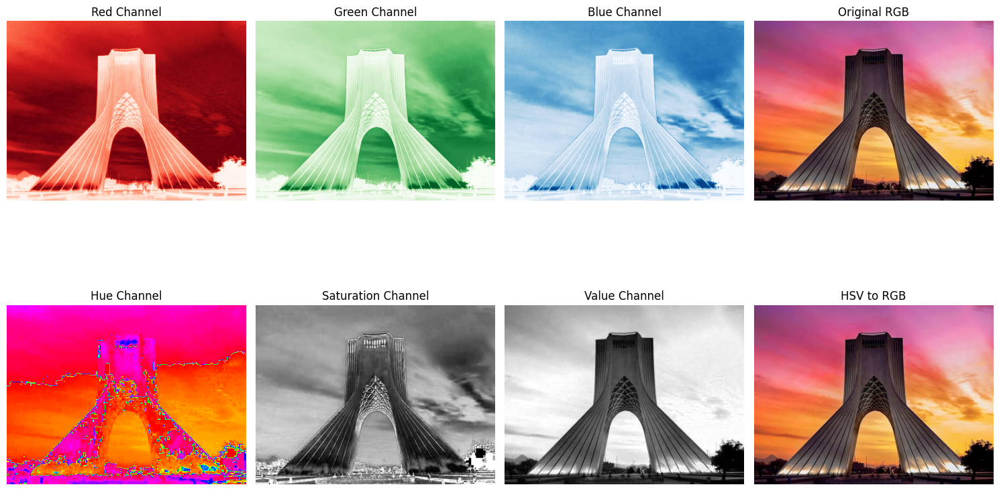

In [6]:
# Separate RGB channels
rChannel = imageRGB[:, :, 0]
gChannel = imageRGB[:, :, 1]
bChannel = imageRGB[:, :, 2]

# Separate HSV channels
hChannel = imageHSV[:, :, 0]
sChannel = imageHSV[:, :, 1]
vChannel = imageHSV[:, :, 2]

plotColorChannels(imageRGB, imageHSV)

Original Image Contrast (std deviation): 58.56
Increased Contrast Image Contrast: 73.92
Decreased Contrast Image Contrast: 29.28


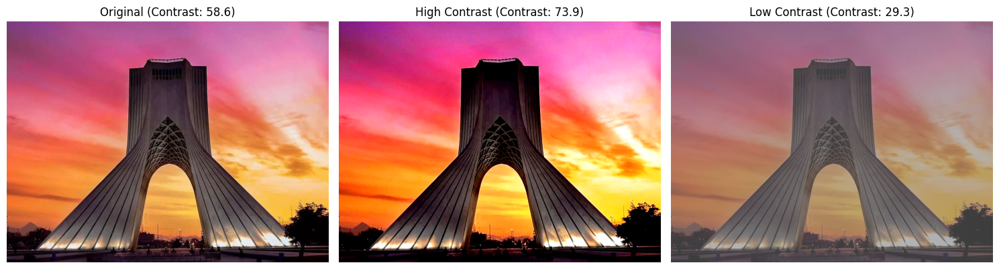

In [7]:
# Helper Function To Calculate Contrast
def calculateContrast(img):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY) if len(img.shape) == 3 else img
    return np.std(gray)

original_contrast = calculateContrast(imageRGB)
print(f"Original Image Contrast (std deviation): {original_contrast:.2f}")

def adjustContrast(image, factor):
    # Convert to float to avoid overflow
    img_float = image.astype(np.float64)
    # Calculate mean intensity
    mean = np.mean(img_float)
    # Apply contrast adjustment
    adjusted = mean + factor * (img_float - mean)
    # Clip values to valid range [0, 255]
    adjusted = np.clip(adjusted, 0, 255)
    return adjusted.astype(np.uint8)

# Increase contrast (factor > 1)
highContrastImg = adjustContrast(imageRGB, 1.5)
highContrastVal = calculateContrast(highContrastImg)
print(f"Increased Contrast Image Contrast: {highContrastVal:.2f}")

# Decrease contrast (factor < 1)
lowContrastImg = adjustContrast(imageRGB, 0.5)
lowContrastVal = calculateContrast(lowContrastImg)
print(f"Decreased Contrast Image Contrast: {lowContrastVal:.2f}")

plotImageComparisons(
    images=[imageRGB, highContrastImg, lowContrastImg],
    titles=[f"Original (Contrast: {original_contrast:.1f})",
            f"High Contrast (Contrast: {highContrastVal:.1f})",
            f"Low Contrast (Contrast: {lowContrastVal:.1f})"],
    cols=3,
    figsize=(15, 5)
)

<p align="justify"><font size="6" color="#A9CCE3"><b>Image Contrast Explained</b></font><br></p>

<p align="justify">
<font size="4" color="#5DADE2"><b>🌗 What is Image Contrast?</b></font><br>
Image contrast refers to the difference in brightness and color that makes objects within an image distinguishable.
It represents the degree of separation between the darkest and brightest regions of an image.
High contrast indicates a wide range of tonal variation, making edges, textures, and details more pronounced.
In contrast, low contrast means there is little tonal variation, causing the image to appear flat, hazy,
or washed out with reduced visual depth.
</p>

<p align="justify">
<font size="4" color="#58D68D"><b>📊 Measuring Contrast:</b></font><br>
Contrast can be quantitatively measured as the <b>standard deviation of pixel intensities</b> within an image —
a higher standard deviation corresponds to greater variation and thus higher contrast.
Other approaches include computing the <b>dynamic range</b> (difference between maximum and minimum pixel values)
or employing more advanced statistical measures such as entropy-based or gradient-based contrast metrics.
</p>

<p align="justify">
<font size="4" color="#F5B041"><b>⚙️ Enhancing Contrast:</b></font><br>
Contrast enhancement is a fundamental image processing operation that improves both the perceptual quality
and analytical value of images. Common enhancement techniques include:
<ul>
<li><b>Linear Contrast Stretching:</b> Expands the range of intensity values to utilize the full spectrum (0–255).</li>
<li><b>Gamma Correction:</b> Adjusts brightness nonlinearly to emphasize details in specific tonal regions.</li>
</ul>
Increasing contrast accentuates details by making dark regions darker and bright regions brighter,
while decreasing contrast compresses the tonal range toward mid-gray values.
</p>

<p align="justify">
<font size="4" color="#F7DC6F"><b>🧠 Importance in Computer Vision:</b></font><br>
Proper contrast is essential in computer vision tasks such as object detection, image segmentation,
and feature extraction. Poorly contrasted images can obscure key visual information, making it harder
for both human observers and algorithms to identify or analyze important details.
Enhancing contrast prior to processing can significantly improve the performance of automated
image recognition and analysis systems.
</p>


<p align="justify"><font size="6" color="#A9CCE3"><b>Contrast Adjustment and Its Mathematical Foundation</b></font><br></p>

<p align="justify">
<font size="4" color="#5DADE2"><b>🔹 Explaining the Code</b></font><br>
The contrast adjustment function modifies image intensities relative to their mean brightness.
</p>

```python
def adjustContrast(image, factor):
    img_float = image.astype(np.float64)
    mean = np.mean(img_float)
    adjusted = mean + factor * (img_float - mean)
    adjusted = np.clip(adjusted, 0, 255)
    return adjusted.astype(np.uint8)
````

<p align="justify">
This function scales the difference between each pixel value and the average intensity by a chosen <b>contrast factor</b>.
A higher factor amplifies intensity variations, while a lower factor reduces them.
</p>

<p align="justify">
<font size="4" color="#58D68D"><b>🔹 Conceptual Explanation</b></font><br>
Let each pixel intensity be denoted as <i>I(x, y)</i>, and let <i>μ</i> represent the mean intensity of the entire image.
The contrast adjustment formula is expressed as:
</p>

<p align="center">
<font color="#AED6F1"><i>I' = μ + α × (I − μ)</i></font>
</p>

<p align="justify">
Where <i>α</i> (alpha) is the contrast factor. This transformation determines how far each pixel's intensity moves away
from the mean brightness:
<ul>
<li><b>α > 1:</b> Expands pixel differences — increases contrast.</li>
<li><b>α < 1:</b> Compresses pixel differences — decreases contrast.</li>
<li><b>α = 1:</b> No change.</li>
</ul>
The <code>np.clip</code> function ensures that all pixel values remain within the valid 8-bit range [0, 255].
</p>

<p align="justify">
<font size="4" color="#F5B041"><b>🔹 Why Standard Deviation Represents Contrast</b></font><br>
In a grayscale image, each pixel has one intensity value <i>I<sub>i</sub></i>. The <b>standard deviation</b> measures how
spread out these intensity values are relative to the mean:
</p>

<p align="center">
<font color="#AED6F1"><i>σ = √( (1/N) Σ (I<sub>i</sub> − μ)² )</i></font>
</p>

<p align="justify">
A higher standard deviation means pixel values are farther from the mean (more variation in brightness), 
which corresponds to <b>higher contrast</b>. Conversely, a lower standard deviation indicates pixel values 
clustered near the mean (less variation), resulting in <b>lower contrast</b>.
Thus, the standard deviation mathematically captures the visual spread of intensities — a direct measure of contrast.
</p>

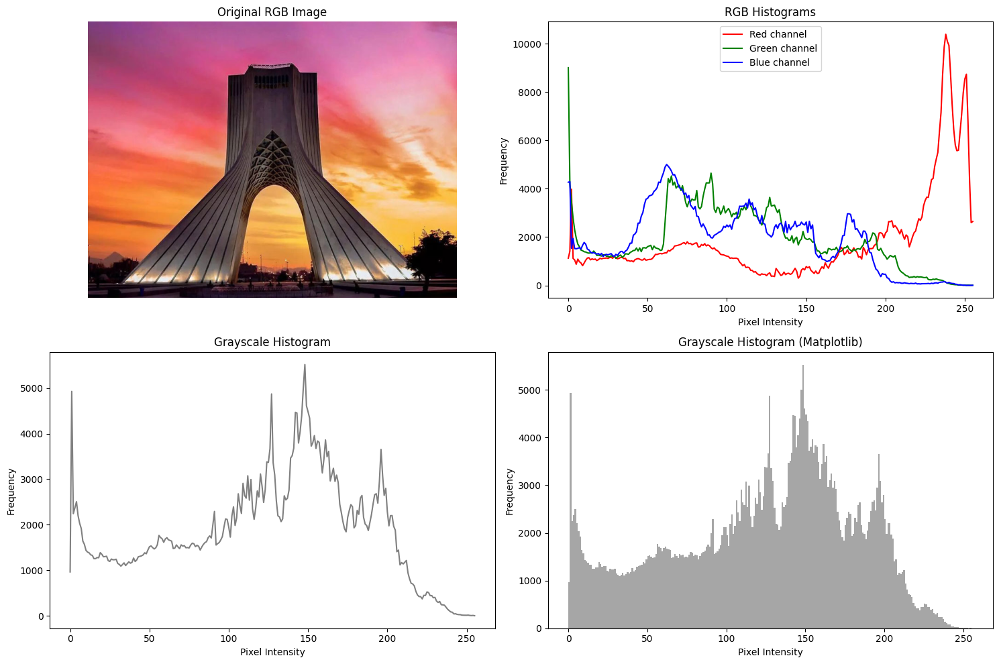

In [8]:
plotHistograms(imageRGB, grayImage)

<p align="justify"><font size="6" color="#A9CCE3"><b>Image Histogram Explained</b></font><br></p>

<p align="justify">
<font size="4" color="#5DADE2"><b>🌗 What is an Image Histogram?</b></font><br>
An image histogram is a graphical representation that shows the distribution of pixel intensities in an image. For grayscale images, it plots the number of pixels for each intensity value (0–255), where 0 represents black and 255 represents white. For color images, histograms can be displayed for each color channel (Red, Green, Blue).
</p>

<p align="justify">
<font size="4" color="#58D68D"><b>📊 Components of a Histogram:</b></font><br>
The key components of an image histogram include:
<ul>
<li><b>X-axis:</b> Represents the range of possible pixel intensity values (0–255 for 8-bit images).</li>
<li><b>Y-axis:</b> Represents the frequency or count of pixels that have a specific intensity value.</li>
<li><b>Peaks:</b> Indicate intensity levels that are common in the image.</li>
<li><b>Valleys:</b> Indicate intensity levels that are rare in the image.</li>
</ul>
</p>

<p align="justify">
<font size="4" color="#F5B041"><b>⚙️ Interpreting Histograms:</b></font><br>
Histograms provide valuable insights into an image's characteristics:
<ul>
<li>A histogram skewed to the left indicates a dark image with many low-intensity (dark) pixels.</li>
<li>A histogram skewed to the right indicates a bright image with many high-intensity (bright) pixels.</li>
<li>A histogram with peaks in the middle suggests good contrast with a range of intensity values.</li>
<li>A narrow histogram indicates low contrast.</li>
<li>A wide histogram indicates high contrast.</li>
</ul>
</p>

<p align="justify">
<font size="4" color="#F7DC6F"><b>🧠 Applications in Computer Vision:</b></font><br>
Image histograms are fundamental in image processing for tasks such as contrast enhancement (e.g., histogram equalization), image thresholding, color analysis, image quality assessment, and preprocessing for computer vision tasks. They provide critical insights into the brightness, contrast, and intensity distribution of images, enabling better analysis and processing.
</p>

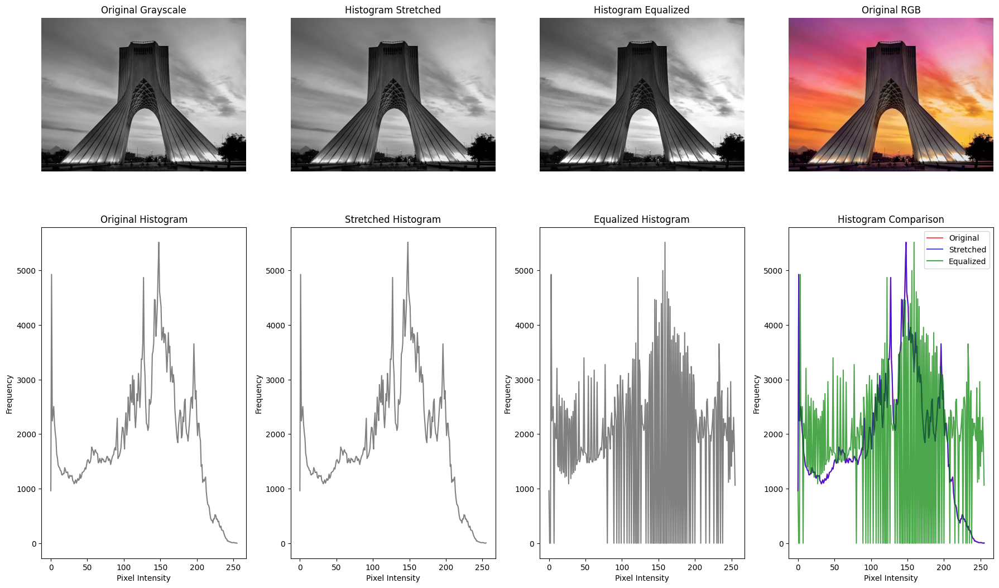

In [9]:
# Apply Histogram Equalization
equalizedImage = cv2.equalizeHist(grayImage)

# Apply Histogram Stretching
# Find the minimum and maximum pixel values
minVal = np.min(grayImage)
maxVal = np.max(grayImage)

# Apply stretching: new_val = (old_val - min) * (255 / (max - min))
stretchedImage = np.zeros(grayImage.shape, dtype=np.uint8)
if maxVal > minVal:  # Avoid division by zero
    stretchedImage = np.floor(((grayImage - minVal) * 255.0) / (maxVal - minVal)).astype(np.uint8)
else:
    stretchedImage = grayImage  # If all pixels are the same value no change needed

histOriginal = cv2.calcHist([grayImage], [0], None, [256], [0, 256])
histStretched = cv2.calcHist([stretchedImage], [0], None, [256], [0, 256])
histEqualized = cv2.calcHist([equalizedImage], [0], None, [256], [0, 256])

plotHistogramComparison(grayImage, stretchedImage, equalizedImage, imageRGB)

<p align="justify"><font size="6" color="#A9CCE3"><b>Histogram Stretching and Histogram Equalization Explained</b></font><br></p>

<p align="justify">
<font size="4" color="#5DADE2"><b>📈 Histogram Stretching (Contrast Stretching):</b></font><br>
Histogram stretching, also known as <b>contrast stretching</b>, is a simple image enhancement technique that improves contrast
by expanding the range of intensity values in an image. Many images have pixel values concentrated within a narrow range
(e.g., between 80 and 180 on a scale of 0–255), resulting in a dull or low-contrast appearance. 
By linearly mapping these values to span the full intensity range, the image appears brighter and more detailed.
</p>

<p align="justify">
Mathematically, histogram stretching can be represented as:
</p>

<p align="center">
<font color="#AED6F1"><i>NewPixel = ((OldPixel - MinPixel) / (MaxPixel - MinPixel)) × (NewMax - NewMin) + NewMin</i></font>
</p>

<p align="justify">
Here, <b>MinPixel</b> and <b>MaxPixel</b> are the minimum and maximum intensity values found in the original image,
while <b>NewMin</b> and <b>NewMax</b> define the desired output intensity range (typically 0–255).
This operation stretches or compresses the histogram, effectively enhancing overall image contrast without altering the relative brightness distribution.
</p>

<p align="justify">
<font size="4" color="#58D68D"><b>📊 Histogram Equalization:</b></font><br>
Histogram equalization is a more advanced technique that redistributes pixel intensities to produce a more uniform histogram.
Instead of stretching the intensity values linearly, this method uses the <b>cumulative distribution function (CDF)</b> of pixel intensities
to spread out the most frequent intensity values. The result is an image where dark regions become brighter and light regions become more detailed,
enhancing visibility across the entire tonal range.
</p>

<p align="justify">
The transformation function for histogram equalization is defined as:
</p>

<p align="center">
<font color="#AED6F1"><i>T(r) = (L - 1) × Σ P(r<sub>k</sub>)</i></font>
</p>

<p align="justify">
where <b>T(r)</b> is the new intensity value, <b>L</b> is the number of gray levels (typically 256), and <b>P(r<sub>k</sub>)</b>
is the probability of occurrence of each intensity level. This process ensures that the output histogram is more evenly distributed,
thereby enhancing global contrast.
</p>

<p align="justify">
<font size="4" color="#F5B041"><b>⚙️ Practical Comparison:</b></font><br>
<ul>
<li><b>Histogram Stretching</b> — Enhances contrast by <i>linearly expanding</i> the existing intensity range. It's simple and fast but limited when the image's intensity distribution is uneven.</li>
<li><b>Histogram Equalization</b> — Improves contrast by <i>redistributing</i> intensities nonlinearly to achieve uniform brightness. It provides better enhancement for images with poor global contrast but may over-amplify noise in some regions.</li>
</ul>
</p>

<p align="justify">
Both techniques play a crucial role in image preprocessing and feature extraction, ensuring that important visual information is more distinguishable for both human interpretation and computer vision algorithms.
</p>


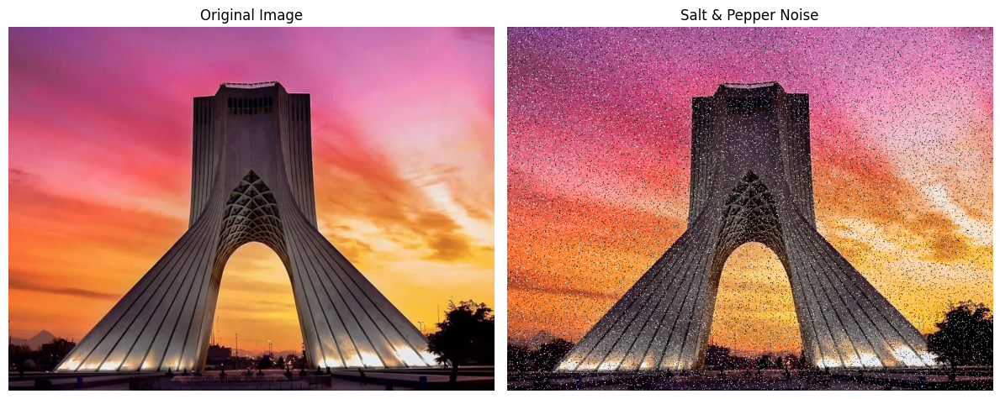

In [10]:
noisyImage = apply_filter(imageRGB, 'salt_pepper', amount=0.1)

plotImageComparisons(
    images=[imageRGB, noisyImage],
    titles=["Original Image", "Salt & Pepper Noise"],
    cols=2,
    figsize=(12, 6)
)

<p align="justify"><font size="6" color="#A9CCE3"><b>Gaussian Noise Explained</b></font><br></p>

<p align="justify">
<font size="4" color="#5DADE2"><b>🔹 What is Gaussian Noise?</b></font><br>
Gaussian noise, also known as normal noise, is a type of statistical noise that follows a normal (Gaussian) distribution.
It is characterized by random variations in pixel intensity values that are distributed according to a bell-shaped curve.
The noise values are drawn from a probability distribution where most values cluster around the mean (typically zero),
and fewer values occur as you move further from the mean. This type of noise is mathematically represented as:
</p>

<p align="center">
<font color="#AED6F1">I<sub>noisy</sub>(x, y) = I<sub>original</sub>(x, y) + N(μ, σ²)</font>
</p>

<p align="justify">
Where N(μ, σ²) represents a random value drawn from a normal distribution with mean μ (typically 0) and variance σ².
</p>

<p align="justify">
<font size="4" color="#58D68D"><b>🔹 Characteristics of Gaussian Noise:</b></font><br>
Gaussian noise has several key properties:
<ul>
<li><b>Random distribution:</b> Noise values follow a normal probability distribution with most values near the mean.</li>
<li><b>Zero mean:</b> Typically, the mean (μ) is zero, meaning the noise adds both positive and negative variations equally.</li>
<li><b>Variance parameter:</b> The variance (σ²) controls the intensity of the noise - higher variance means more noise.</li>
</ul>
</p>

<p align="justify">
<font size="4" color="#F5B041"><b>🔹 Common Sources:</b></font><br>
Gaussian noise commonly occurs in digital images due to:
<ul>
<li><b>Sensor limitations:</b> Electronic noise in camera sensors, especially in low light conditions.</li>
<li><b>Thermal effects:</b> Heat in electronic components causing random fluctuations.</li>
<li><b>Quantization errors:</b> Rounding errors during analog-to-digital conversion.</li>
<li><b>Transmission processes:</b> Electronic circuitry during image acquisition and processing.</li>
</ul>
</p>

<p align="justify">
<font size="4" color="#F7DC6F"><b>🔹 Difference from Salt and Pepper Noise:</b></font><br>
While salt and pepper noise adds extreme values (white or black pixels) to random locations,
Gaussian noise adds small random variations to every pixel in the image. This results in a
more subtle, "fuzziness" effect rather than distinct white and black dots scattered throughout the image.
Gaussian noise is more representative of natural noise in real-world imaging systems.
</p>

<p align="justify">
<font size="4" color="#A569BD"><b>🔹 Reducing Gaussian Noise:</b></font><br>
Common techniques to reduce Gaussian noise include Gaussian blurring, bilateral filtering, and
wavelet denoising. However, noise reduction must be balanced against preserving image detail
and sharpness, as aggressive noise reduction can result in overly smooth images with reduced quality.
</p>

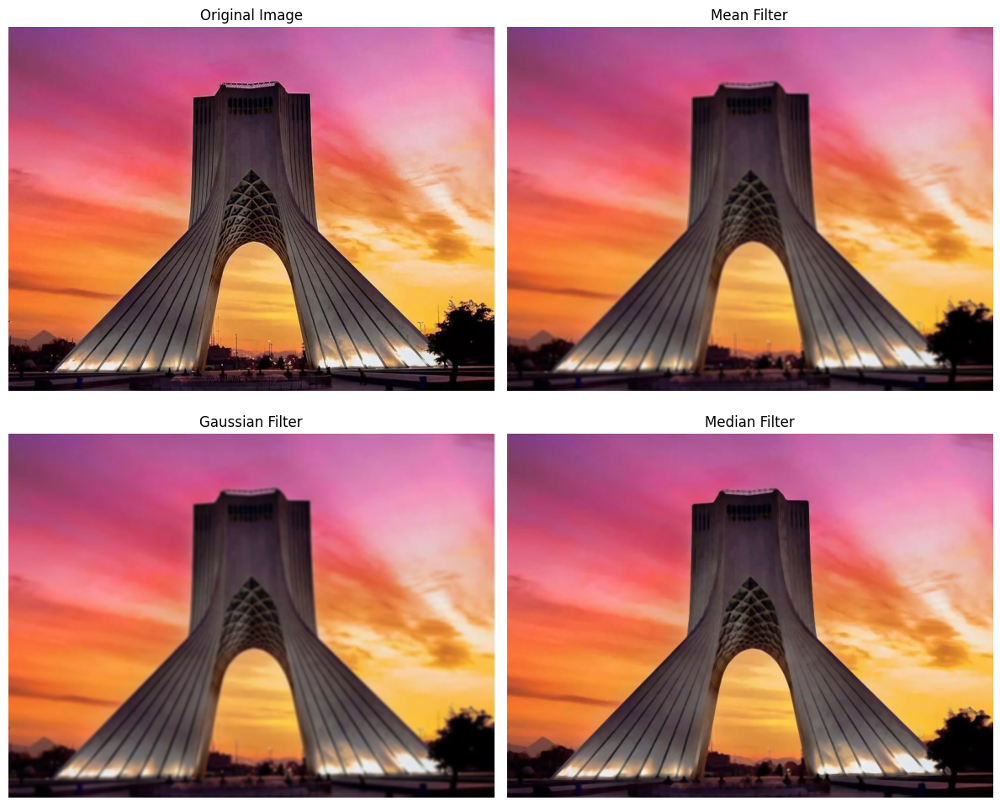

In [11]:
mean_filtered = apply_filter(imageRGB, 'mean', size=5)
gaussian_filtered = apply_filter(imageRGB, 'gaussian', size=8, sigma=2)
median_filtered = apply_filter(imageRGB, 'median', size=5)

plotImageComparisons(
    images=[imageRGB, mean_filtered, gaussian_filtered, median_filtered],
    titles=["Original Image", "Mean Filter", "Gaussian Filter", "Median Filter"],
    cols=2,
    figsize=(12, 10)
)

<p align="justify"><font size="6" color="#A9CCE3"><b>Kernel Concept in Image Processing Explained</b></font><br></p>

<p align="justify">
<font size="4" color="#5DADE2"><b>🌗 What is a Kernel (Convolution Matrix)?</b></font><br>
In image processing, a kernel (also called a convolution matrix, mask, or filter) is a small matrix used to apply various effects to images, such as blurring, sharpening, embossing, or edge detection. Typically a square matrix (e.g., 3×3, 5×5, or 7×7), it contains numerical values that define the specific transformation. The process of applying a kernel to an image is known as convolution.
</p>

<p align="justify">
<font size="4" color="#58D68D"><b>📊 How Kernels Work:</b></font><br>
The kernel is applied to each pixel in the image through a convolution operation, which involves the following steps:
<ul>
<li><b>Overlay:</b> Position the kernel over the image, aligning its center with a specific pixel.</li>
<li><b>Multiply:</b> Multiply each kernel value by the corresponding pixel value beneath it.</li>
<li><b>Sum:</b> Add up all the products from the multiplication step.</li>
<li><b>Replace:</b> Replace the original pixel value with the computed sum.</li>
<li><b>Repeat:</b> Slide the kernel to the next pixel and repeat the process across the entire image.</li>
</ul>
For example, for a 3×3 kernel and a 3×3 region of pixel values, the convolution is expressed as:
<p align="center"><font color="#AED6F1">NewPixel = Σ(kernel<sub>ij</sub> × pixel<sub>ij</sub>)</font></p>
</p>

<p align="justify">
<font size="4" color="#F5B041"><b>⚙️ Common Kernel Applications and Examples:</b></font><br>
Kernels are widely used in image processing for various purposes:
<ul>
<li><b>Gaussian Blur:</b> Reduces image noise and detail, with the Gaussian kernel weighted toward the center pixel for a smooth blurring effect.</li>
<li><b>Edge Detection:</b> Kernels like Sobel, Prewitt, or Canny operators highlight regions of high spatial frequency to detect edges.</li>
<li><b>Sharpening:</b> Enhances image details by accentuating edges and fine features.</li>
<li><b>Embossing:</b> Creates a 3D shadow effect, making the image appear raised from the canvas.</li>
<li><b>Median Filtering:</b> Though not strictly linear, this technique removes noise while preserving edges.</li>
</ul>
</p>

<p align="justify">
<font size="4" color="#F7DC6F"><b>🧠 Mathematical Foundation:</b></font><br>
Convolution in 2D is mathematically defined as:
<p align="center"><font color="#AED6F1">(f * g)(x,y) = Σ Σ f(m,n) × g(x-m, y-n)</font></p>
Here, <i>f</i> represents the image, <i>g</i> is the kernel, and the double sum computes the weighted sum of neighborhood values. The kernel is typically flipped horizontally and vertically before application to adhere to the mathematical definition of convolution.
</p>

<p align="justify">
<font size="4" color="#A569BD"><b>🔧 Implementation Process:</b></font><br>
To apply a kernel to an image, the following steps are performed:
<ul>
<li><b>Padding:</b> Extend the image borders to maintain output size and handle edge pixels, using strategies like zero-padding, replicate-padding, or symmetric-padding.</li>
<li><b>Iteration:</b> Slide the kernel across the image, pixel by pixel.</li>
<li><b>Calculation:</b> Multiply corresponding kernel and pixel values, then sum the results.</li>
<li><b>Output:</b> Place the calculated value in the corresponding position of the output image.</li>
</ul>
</p>

<p align="justify">
<font size="4" color="#5B2C6F"><b>💡 Advanced Considerations:</b></font><br>
Kernels can be combined through convolution to create complex effects. The sum of kernel values affects image brightness: kernels summing to 1 preserve brightness, while those summing near 0 highlight changes and reduce brightness. Normalization may be needed to keep output values within the expected range (e.g., 0–255 for 8-bit images).
</p>

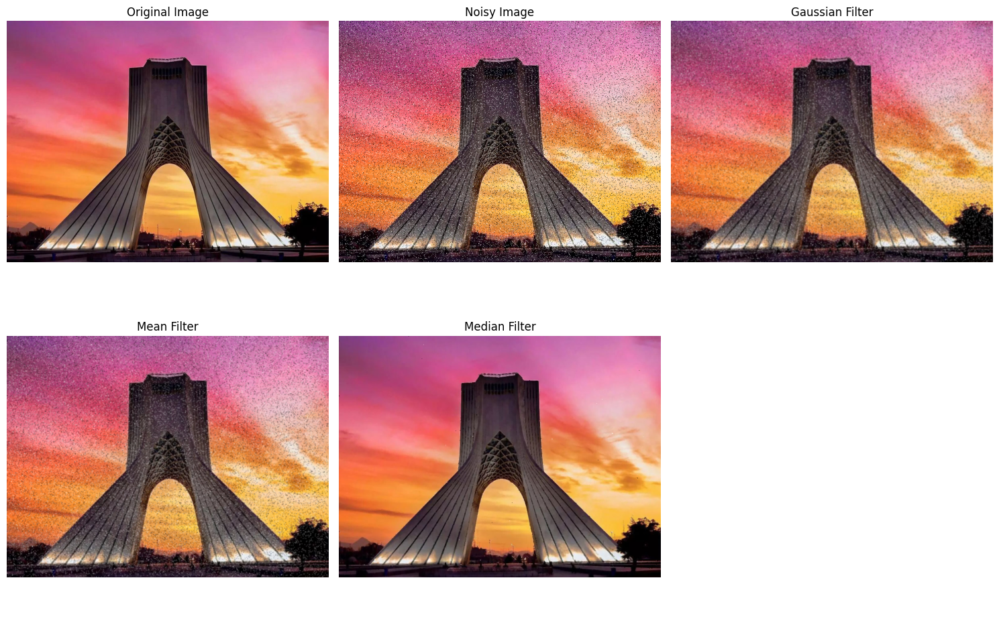

In [12]:
gaussian_filtered = apply_filter(noisyImage, 'gaussian', size=5, sigma=1)
mean_filtered = apply_filter(noisyImage, 'mean', size=3)
median_filtered = apply_filter(noisyImage, 'median', size=3)

plotImageComparisons(
    images=[imageRGB, noisyImage, gaussian_filtered, mean_filtered, median_filtered],
    titles=["Original Image", "Noisy Image", "Gaussian Filter", "Mean Filter", "Median Filter"],
    cols=3,
    figsize=(15, 10)
)

<p align="justify"><font size="6" color="#A9CCE3"><b>Justification: Why Median Filter is Best for Salt and Pepper Noise</b></font><br></p>

<p align="justify">
<font size="4" color="#5DADE2"><b>🌗 Median Filter's Effectiveness:</b></font><br>
The median filter is the most effective for removing salt and pepper noise due to its unique approach to noise reduction. Unlike linear filters such as Gaussian or mean filters that compute the average of pixel values in a neighborhood, the median filter selects the median value from the neighborhood. This approach is particularly effective for salt and pepper noise because:
<ul>
<li>It preserves edges and fine details in the image better than linear filters.</li>
<li>It is less sensitive to extreme values (outliers), which is exactly what salt and pepper noise represents.</li>
<li>For salt and pepper noise, the extreme values are either 0 (black) or 255 (white), while the median filter replaces noisy pixels with values that are more representative of their surroundings.</li>
</ul>
</p>

<p align="justify">
<font size="4" color="#F5B041"><b>⚙️ Comparison with Other Filters:</b></font><br>
In contrast, mean and Gaussian filters can spread noise throughout the image because they average pixel values, including the extremely noisy pixels. This causes white and black pixels to appear as grayish artifacts around the noise. The median filter, however, effectively removes the noise if the filter size is appropriately chosen relative to the noise density.
</p>

<p align="justify">
<font size="4" color="#F7DC6F"><b>🧠 Practical Considerations:</b></font><br>
The effectiveness of the median filter depends on the filter size. For salt and pepper noise, a 3×3 or 5×5 kernel is typically sufficient. If the filter size is too small relative to the noise density, some noise may remain. If the filter size is too large, the image may lose important details. Overall, the median filter strikes the best balance between noise removal and detail preservation for salt and pepper noise specifically.
</p>

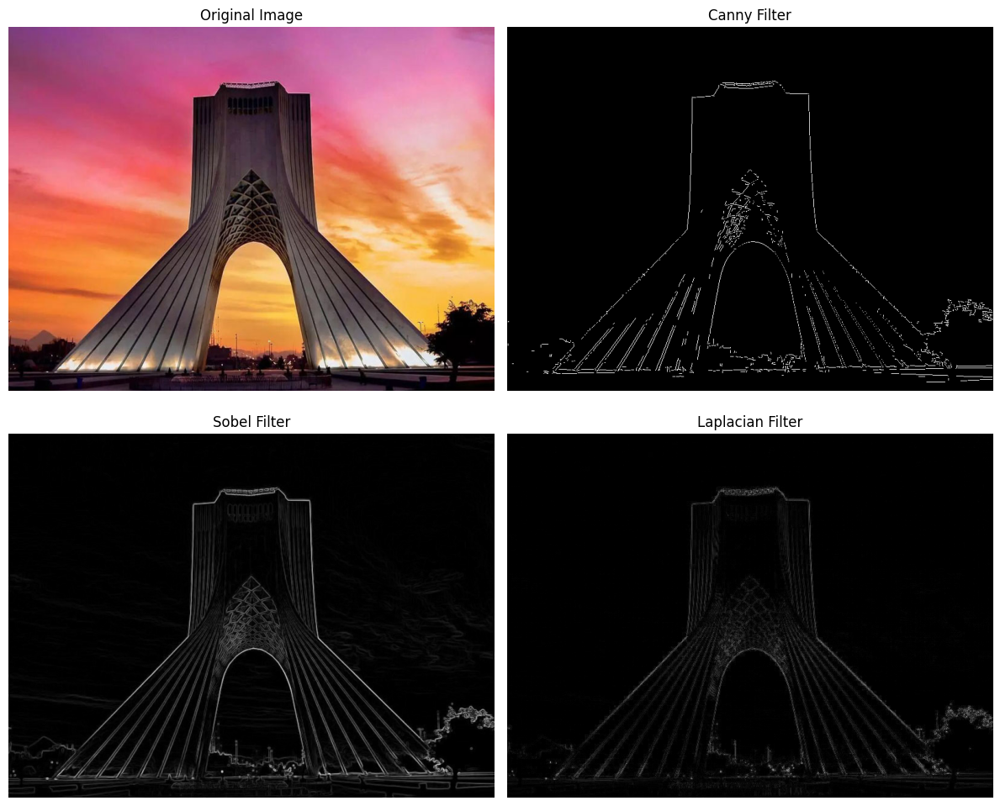

In [13]:
canny_filtered = apply_filter(imageRGB, 'canny')
sobel_filtered = apply_filter(imageRGB, 'sobel')
laplacian_filtered = apply_filter(imageRGB, 'laplacian')

plotImageComparisons(
    images=[imageRGB, canny_filtered, sobel_filtered, laplacian_filtered],
    titles=["Original Image", "Canny Filter", "Sobel Filter", "Laplacian Filter"],
    cols=2,
    figsize=(12, 10)
)

<p align="justify"><font size="6" color="#A9CCE3"><b>Edge Detection Methods: Canny, Sobel, and Laplacian Explained</b></font><br></p>

<p align="justify">
<font size="4" color="#5DADE2"><b>🌗 Canny Edge Detection:</b></font><br>
The Canny edge detector, developed by John F. Canny in 1986, is a multi-stage algorithm widely regarded as one of the most effective methods for edge detection. It involves four key steps:
<ul>
<li>Noise reduction using Gaussian smoothing.</li>
<li>Gradient calculation to identify intensity changes.</li>
<li>Non-maximum suppression to thin the edges.</li>
<li>Double thresholding with hysteresis to determine true edges.</li>
</ul>
</p>

<p align="justify">
<font size="4" color="#58D68D"><b>📊 Kernel Type:</b></font><br>
The Canny method does not rely on a single fixed kernel. Instead, it computes gradients using derivatives of a Gaussian function in both horizontal and vertical directions.
</p>

<p align="justify">
<font size="4" color="#F5B041"><b>⚙️ Example:</b></font><br>
In code, Canny edge detection is applied using <code>apply_filter(imageRGB, 'canny')</code>, which internally leverages OpenCV's <code>cv2.Canny()</code> function. This method excels at detecting true edges while minimizing noise.
</p>

<p align="justify">
<font size="4" color="#5DADE2"><b>🌊 Sobel Edge Detection:</b></font><br>
The Sobel operator detects edges by calculating the gradient of the image intensity function. It uses two 3×3 kernels to approximate derivatives in the horizontal and vertical directions, making it particularly sensitive to horizontal and vertical edges.
</p>

<p align="justify">
<font size="4" color="#58D68D"><b>📊 Kernel Type:</b></font><br>
The Sobel operator employs two 3×3 kernels:
<ul>
<li><b>Horizontal (Gx):</b> <i>[[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]</i></li>
<li><b>Vertical (Gy):</b> <i>[[-1, -2, -1], [0, 0, 0], [1, 2, 1]]</i></li>
</ul>
</p>

<p align="justify">
<font size="4" color="#F5B041"><b>⚙️ Example:</b></font><br>
In code, Sobel edge detection is applied using <code>apply_filter(imageRGB, 'sobel')</code>. This method highlights regions of high spatial frequency corresponding to edges.
</p>

<p align="justify">
<font size="4" color="#5DADE2"><b>🌀 Laplacian Edge Detection:</b></font><br>
The Laplacian operator, a second-order derivative method, detects edges by calculating the sum of second-order partial derivatives of the image intensity function. It highlights regions of rapid intensity change and detects edges in all directions but is more sensitive to noise compared to Canny and Sobel.
</p>

<p align="justify">
<font size="4" color="#58D68D"><b>📊 Kernel Type:</b></font><br>
The Laplacian operator typically uses a 3×3 kernel, such as:
<ul>
<li><i>[[0, 1, 0], [1, -4, 1], [0, 1, 0]]</i></li>
<li><i>[[1, 1, 1], [1, -8, 1], [1, 1, 1]]</i></li>
</ul>
</p>

<p align="justify">
<font size="4" color="#F5B041"><b>⚙️ Example:</b></font><br>
In code, Laplacian edge detection is applied using <code>apply_filter(imageRGB, 'laplacian')</code>. This method produces sharp edges but may introduce more noise.
</p>

<p align="justify">
<font size="4" color="#F7DC6F"><b>🧠 Comparison of Methods:</b></font><br>
<ul>
<li><b>Canny:</b> Most effective for detecting true edges while minimizing noise; computationally intensive.</li>
<li><b>Sobel:</b> Effective for detecting horizontal and vertical edges; less sensitive to noise than Laplacian.</li>
<li><b>Laplacian:</b> Detects edges in all directions; highly sensitive to noise but computationally efficient.</li>
</ul>
</p>

In [14]:
cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    print(f"Error: Could not open video file {VIDEO_PATH}")
else:
    num_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)

    print(f"Number of frames: {num_frames}")
    print(f"FPS: {fps}")

    frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    # Define the codec and create VideoWriter object to save the noisy video
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out = cv2.VideoWriter('noisy_vid.mp4', fourcc, fps, (frame_width, frame_height))

    # Process each frame
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        noisy_frame = apply_filter(frame, 'salt_pepper', amount=0.1)
        out.write(noisy_frame)

    # Release everything
    cap.release()
    out.release()

    print("Noisy video saved as noisy_vid.mp4")

Number of frames: 545
FPS: 30.0
Noisy video saved as noisy_vid.mp4
